# 11 Prediction Testing on Unseen Images

## Objective
Perform end-to-end inference testing on test/unseen images using the trained models, evaluate per-class prediction confidence, and analyze correct vs incorrect predictions.

**Prerequisites:** All previous training notebooks (01-10)
**Next Step:** `12_tflite_conversion.ipynb`

## 1. Import Libraries

In [1]:
import sys
import os

sys.path.insert(0, '../utils')

from model_utils import load_model
from visualization_utils import plot_predictions_with_confidence

import numpy as np
import json
import matplotlib.pyplot as plt
import pandas as pd

print("✓ Libraries imported successfully!")


✓ Libraries imported successfully!


## 2. Load Data and Best Model

In [ ]:
import sys
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras.utils import to_categorical

sys.path.insert(0, '../utils')

from model_utils import load_model
from visualization_utils import plot_predictions_with_confidence
from npz_consolidator import load_consolidated_arrays

print("Loading test data from the current preprocessed split folders...\n")

project_root = Path.cwd().resolve()
if not (project_root / "results").exists():
    project_root = project_root.parent

base_path = project_root / "results" / "preprocessed_data_efficient"
legacy_path = project_root / "results" / "preprocessed_data"

if base_path.exists() and (base_path / "test_images").exists():
    X_test = load_consolidated_arrays(str(base_path), split_type="test")

    with open(base_path / "image_metadata.json", "r") as f:
        metadata = json.load(f)
    with open(base_path / "split_indices.json", "r") as f:
        split_info = json.load(f)
    with open(base_path / "label_encoding.json", "r") as f:
        label_encoding = json.load(f)

    labels_all = np.array(metadata["labels"])
    test_indices = split_info["test_indices"]
    y_test = to_categorical(labels_all[test_indices], num_classes=len(label_encoding))

    num_classes = len(label_encoding)
    reverse_encoding = {v: k for k, v in label_encoding.items()}
    class_names = [reverse_encoding[i] for i in range(num_classes)]

    print(f"✓ Loaded test images from: {base_path / 'test_images'}")
    print(f"✓ Test split size: {X_test.shape[0]}")
elif legacy_path.exists():
    X_test = np.load(legacy_path / "X_test.npy")
    y_test = np.load(legacy_path / "y_test.npy")

    with open(legacy_path / "label_encoding.json", "r") as f:
        label_encoding = json.load(f)

    num_classes = len(label_encoding)
    reverse_encoding = {v: k for v in label_encoding.items()}
    class_names = [reverse_encoding[i] for i in range(num_classes)]

    print("✓ Loaded test data from legacy preprocessed folder.")
else:
    raise FileNotFoundError("No test split data found. Expected results/preprocessed_data_efficient/test_images or results/preprocessed_data/X_test.npy")

print(f"✓ Test data loaded: {X_test.shape}")


def prepare_inputs_for_model(images, model):
    images = np.asarray(images, dtype="float32")
    input_shape = getattr(model, "input_shape", None)
    if not input_shape or len(input_shape) < 4:
        return images

    target_height = input_shape[1]
    target_width = input_shape[2]
    if target_height is None or target_width is None:
        return images

    current_height, current_width = images.shape[1], images.shape[2]
    if (current_height, current_width) == (target_height, target_width):
        return images

    resized = tf.image.resize(images, size=(target_height, target_width), method=tf.image.ResizeMethod.BILINEAR)
    return tf.cast(resized, tf.float32).numpy()

print("\nChecking availability of the three model files before evaluation...\n")

model_specs = [
    {
        "name": "EfficientNetB0",
        "candidates": [
            project_root / "models" / "efficientnetb0" / "efficientnetb0_final.h5",
            project_root / "models" / "cnn" / "efficientnetb0" / "efficientnetb0_final.h5",
        ],
    },
    {
        "name": "MobileNetV2",
        "candidates": [
            project_root / "models" / "mobilenet" / "mobilenet_v2_final.h5",
            project_root / "models" / "mobilenetv2" / "mobilenet_v2_final.h5",
        ],
    },
    {
        "name": "ResNet50",
        "candidates": [
            project_root / "models" / "resnet50" / "resnet50_final.h5",
        ],
    },
]

resolved_model_specs = []
missing_models = []
for spec in model_specs:
    resolved_path = None
    for candidate in spec["candidates"]:
        if candidate.exists():
            resolved_path = candidate
            break

    if resolved_path is None:
        missing_models.append((spec["name"], [str(c) for c in spec["candidates"]]))
    else:
        resolved_model_specs.append({
            "name": spec["name"],
            "path": resolved_path,
        })
        print(f"✓ Found {spec['name']}: {resolved_path}")

if missing_models:
    print("\nMissing required model files:")
    for name, candidates in missing_models:
        print(f"- {name}: {', '.join(candidates)}")
    raise FileNotFoundError("One or more required model files are missing. Fix the paths above before running evaluation.")

print("\nAll required models were found. Starting evaluation...\n")

model_results = []
for spec in resolved_model_specs:
    model_path = spec["path"]
    model = load_model(str(model_path))
    eval_images = prepare_inputs_for_model(X_test, model)
    predictions = model.predict(eval_images, verbose=0)
    pred_labels_idx = np.argmax(predictions, axis=1)
    true_labels_idx = np.argmax(y_test, axis=1)
    pred_labels = np.array([class_names[i] for i in pred_labels_idx])
    true_labels = np.array([class_names[i] for i in true_labels_idx])
    confidence = np.max(predictions, axis=1)
    accuracy = np.mean(pred_labels == true_labels)

    model_results.append({
        "name": spec["name"],
        "path": str(model_path),
        "model": model,
        "predictions": predictions,
        "confidence": confidence,
        "accuracy": float(accuracy),
        "pred_labels": pred_labels,
        "true_labels": true_labels,
        "pred_labels_idx": pred_labels_idx,
        "true_labels_idx": true_labels_idx,
    })

    print(f"✓ {spec['name']}: accuracy = {accuracy:.4f}")

if not model_results:
    raise FileNotFoundError("No trained model files were found for evaluation.")

best_result = max(model_results, key=lambda item: item["accuracy"])
best_model_name = best_result["name"]
best_model_path = best_result["path"]
model = best_result["model"]
predictions = best_result["predictions"]
confidence = best_result["confidence"]
accuracy = best_result["accuracy"]
pred_labels = best_result["pred_labels"]
true_labels = best_result["true_labels"]
pred_labels_idx = best_result["pred_labels_idx"]
true_labels_idx = best_result["true_labels_idx"]

print(f"\n🏆 Best model selected: {best_model_name} ({accuracy:.4f})")
print(f"   Path: {best_model_path}")

comparison_df = pd.DataFrame([
    {"Model": item["name"], "Accuracy": item["accuracy"], "Path": item["path"]}
    for item in model_results
]).sort_values("Accuracy", ascending=False)
print("\nModel comparison:")
print(comparison_df.to_string(index=False))

comparison_df.to_csv('../results/reports/model_comparison.csv', index=False)
print("\n✓ Saved: model_comparison.csv")

Loading test data from the current preprocessed split folders...

Loading 860 images from test set...


  Loaded 100/860 images...
  Loaded 200/860 images...
  Loaded 300/860 images...
  Loaded 400/860 images...
  Loaded 500/860 images...
  Loaded 600/860 images...
  Loaded 700/860 images...
  Loaded 800/860 images...
✓ Consolidated test set: (860, 224, 224, 3), dtype: float32

✓ Loaded test images from: D:\cnn_model\results\preprocessed_data_efficient\test_images
✓ Test split size: 860
✓ Test data loaded: (860, 224, 224, 3)

Checking availability of the three model files before evaluation...

✓ Found EfficientNetB0: D:\cnn_model\models\efficientnetb0\efficientnetb0_final.h5
✓ Found MobileNetV2: D:\cnn_model\models\mobilenet\mobilenet_v2_final.h5
✓ Found ResNet50: D:\cnn_model\models\resnet50\resnet50_final.h5

All required models were found. Starting evaluation...



✓ EfficientNetB0: accuracy = 0.0267
✓ MobileNetV2: accuracy = 0.9012


## 3. Make Predictions

In [ ]:
print("\nMaking predictions on test set...\n")

# Predict
predictions = model.predict(X_test, verbose=0)
pred_labels_idx = np.argmax(predictions, axis=1)
true_labels_idx = np.argmax(y_test, axis=1)

# Convert indices to class names
pred_labels = np.array([class_names[i] for i in pred_labels_idx])
true_labels = np.array([class_names[i] for i in true_labels_idx])

# Get confidence scores
confidence = np.max(predictions, axis=1)

# Calculate accuracy
accuracy = np.mean(pred_labels == true_labels)

print(f"✓ Predictions completed")
print(f"  Test Set Size: {len(X_test)}")
print(f"  Accuracy: {accuracy:.4f}")
print(f"  Mean Confidence: {confidence.mean():.4f}")
print(f"  Min Confidence: {confidence.min():.4f}")
print(f"  Max Confidence: {confidence.max():.4f}")


Making predictions on test set...



KeyboardInterrupt: 

## 4. Analyze Prediction Confidence


CONFIDENCE ANALYSIS

✓ Saved: prediction_confidence.png


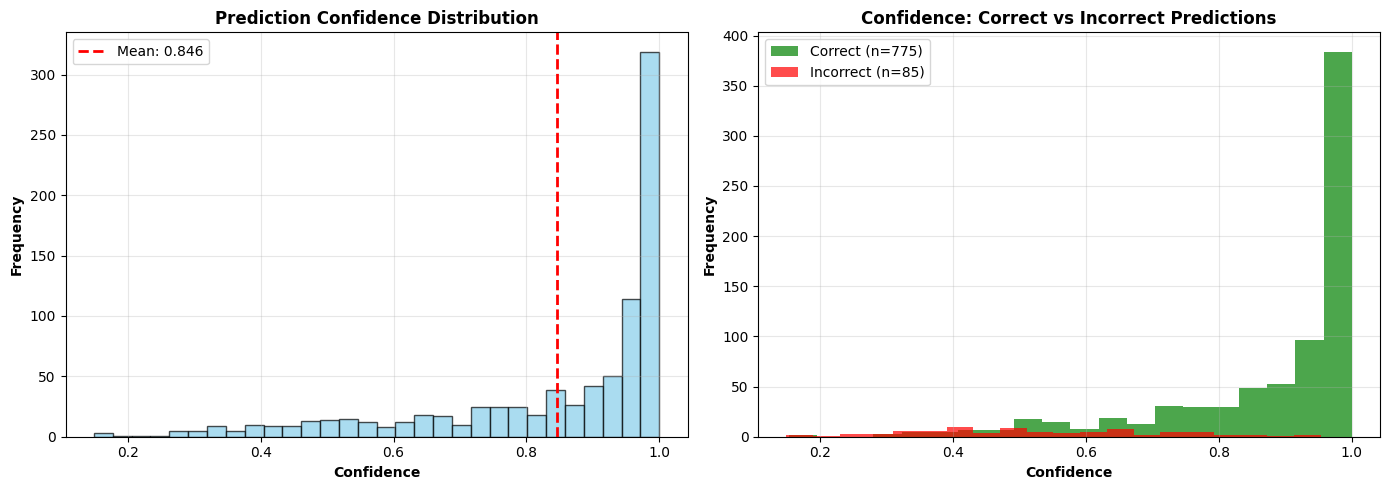

In [5]:
print("\n" + "="*70)
print("CONFIDENCE ANALYSIS")
print("="*70 + "\n")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confidence distribution
axes[0].hist(confidence, bins=30, edgecolor='black', alpha=0.7, color='skyblue')
axes[0].axvline(confidence.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {confidence.mean():.3f}')
axes[0].set_xlabel('Confidence', fontweight='bold')
axes[0].set_ylabel('Frequency', fontweight='bold')
axes[0].set_title('Prediction Confidence Distribution', fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Correct vs Incorrect confidence
correct_mask = (pred_labels == true_labels)
correct_confidence = confidence[correct_mask]
incorrect_confidence = confidence[~correct_mask]

axes[1].hist(correct_confidence, bins=20, alpha=0.7, label=f'Correct (n={len(correct_confidence)})', color='green')
axes[1].hist(incorrect_confidence, bins=20, alpha=0.7, label=f'Incorrect (n={len(incorrect_confidence)})', color='red')
axes[1].set_xlabel('Confidence', fontweight='bold')
axes[1].set_ylabel('Frequency', fontweight='bold')
axes[1].set_title('Confidence: Correct vs Incorrect Predictions', fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../results/plots/prediction_confidence.png', dpi=300, bbox_inches='tight')
print("✓ Saved: prediction_confidence.png")

## 5. Display Correct Predictions


Showing correct predictions...

✓ Saved: correct_predictions.png


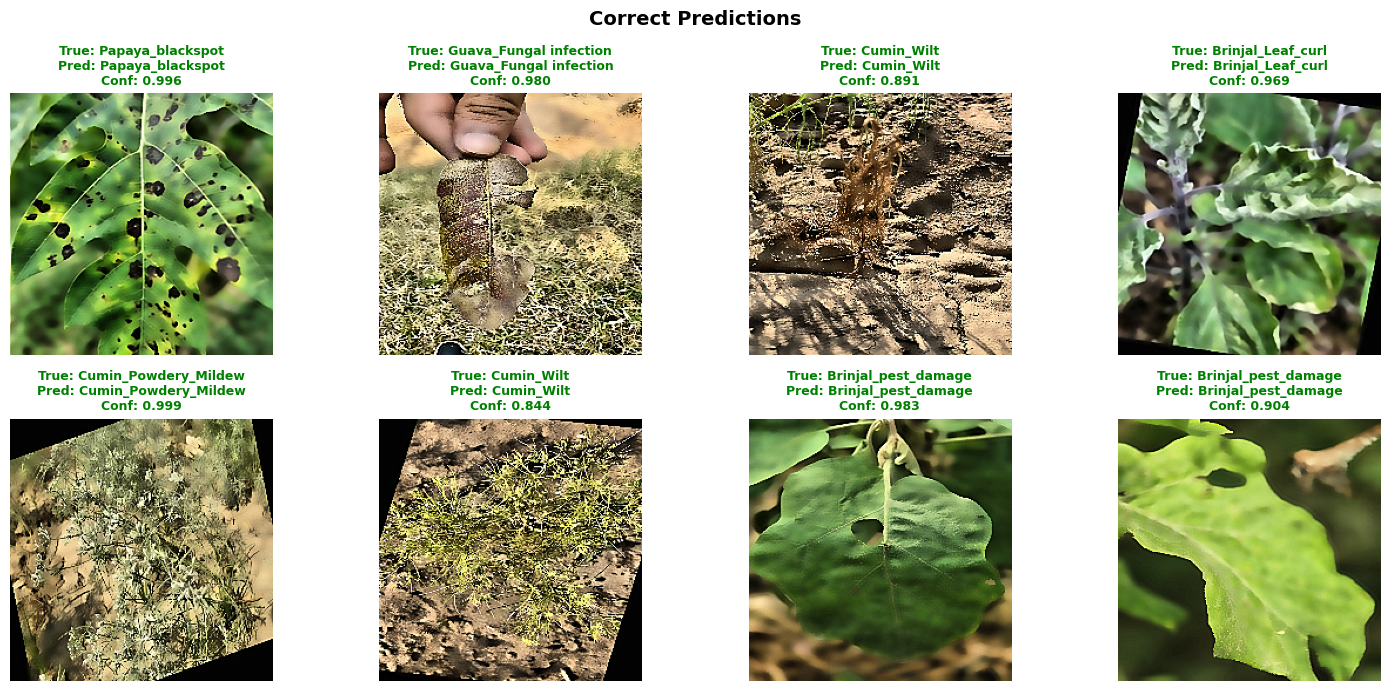

In [6]:
print("\nShowing correct predictions...\n")

# Get correct predictions
correct_indices = np.where(correct_mask)[0]
sample_correct_idx = np.random.choice(correct_indices, min(8, len(correct_indices)), replace=False)

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
axes = axes.flatten()

for plot_idx, img_idx in enumerate(sample_correct_idx):
    ax = axes[plot_idx]
    img = X_test[img_idx]

    ax.imshow(img)
    ax.set_title(f"True: {true_labels[img_idx]}\nPred: {pred_labels[img_idx]}\nConf: {confidence[img_idx]:.3f}",
                 fontweight='bold', color='green', fontsize=9)
    ax.axis('off')

plt.suptitle('Correct Predictions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/plots/correct_predictions.png', dpi=300, bbox_inches='tight')
print("✓ Saved: correct_predictions.png")

## 6. Display Incorrect Predictions


Showing incorrect predictions (misclassifications)...

✓ Saved: misclassified_predictions.png


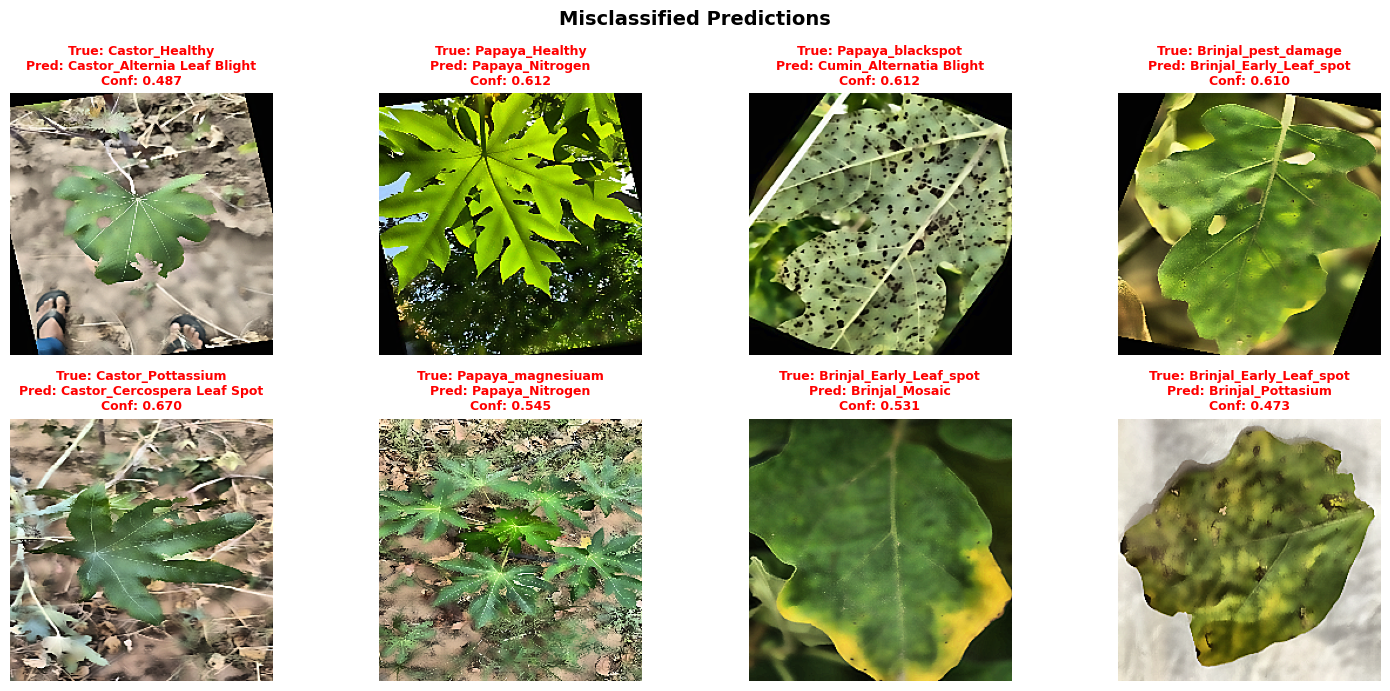

In [7]:
print("\nShowing incorrect predictions (misclassifications)...\n")

# Get incorrect predictions
incorrect_indices = np.where(~correct_mask)[0]

if len(incorrect_indices) > 0:
    sample_incorrect_idx = np.random.choice(incorrect_indices, min(8, len(incorrect_indices)), replace=False)

    fig, axes = plt.subplots(2, 4, figsize=(15, 7))
    axes = axes.flatten()

    for plot_idx, img_idx in enumerate(sample_incorrect_idx):
        ax = axes[plot_idx]
        img = X_test[img_idx]

        ax.imshow(img)
        ax.set_title(f"True: {true_labels[img_idx]}\nPred: {pred_labels[img_idx]}\nConf: {confidence[img_idx]:.3f}",
                     fontweight='bold', color='red', fontsize=9)
        ax.axis('off')

    plt.suptitle('Misclassified Predictions', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('../results/plots/misclassified_predictions.png', dpi=300, bbox_inches='tight')
    print("✓ Saved: misclassified_predictions.png")
else:
    print("✓ No misclassifications found!")

## 7. Per-Class Prediction Statistics

In [12]:
print("\n" + "="*70)
print("PER-CLASS PREDICTION STATISTICS")
print("="*70 + "\n")

class_stats = []
for class_idx, class_name in enumerate(class_names):
    class_mask = (true_labels_idx == class_idx)

    if class_mask.sum() > 0:
        class_correct = (pred_labels_idx[class_mask] == class_idx).sum()
        class_accuracy = class_correct / class_mask.sum()
        class_avg_confidence = confidence[class_mask].mean()

        class_stats.append({
            'Class': class_name,
            'Samples': int(class_mask.sum()),
            'Correct': int(class_correct),
            'Accuracy': f"{class_accuracy:.4f}",
            'Avg_Confidence': f"{class_avg_confidence:.4f}"
        })

class_stats_df = pd.DataFrame(class_stats).sort_values('Accuracy', ascending=False)
print(class_stats_df.to_string(index=False))

# Save stats
class_stats_df.to_csv('../results/reports/per_class_prediction_stats.csv', index=False)
print("\n✓ Saved: per_class_prediction_stats.csv")


PER-CLASS PREDICTION STATISTICS

                          Class  Samples  Correct Accuracy Avg_Confidence
           Cumin_Powdery_Mildew       17       17   1.0000         0.9706
   Castor_Bacterial Leaf Blight       23       23   1.0000         0.8220
                Papaya_Nitrogen       13       13   1.0000         0.8418
     Papaya_Bacterial Leaf Spot       28       28   1.0000         0.8994
              Guava_Rust_fungal       15       15   1.0000         0.9899
               Guava_phosphorus       20       20   1.0000         0.9590
         Guava_Fungal infection       19       19   1.0000         0.9153
                  Guava_Healthy       24       24   1.0000         0.9156
         Cumin_insect_infection       21       21   1.0000         0.9057
           Castor_Peast_disease       16       16   1.0000         0.8375
    Castor_Cercospera Leaf Spot       18       18   1.0000         0.8693
               Papaya_Pottasium       18       18   1.0000         0.9075
  Br

## 8. Low Confidence Predictions


LOW CONFIDENCE PREDICTIONS

Predictions with confidence < 0.7: 170 (19.77%)
Accuracy on low confidence predictions: 0.6000
✓ Saved: low_confidence_predictions.png


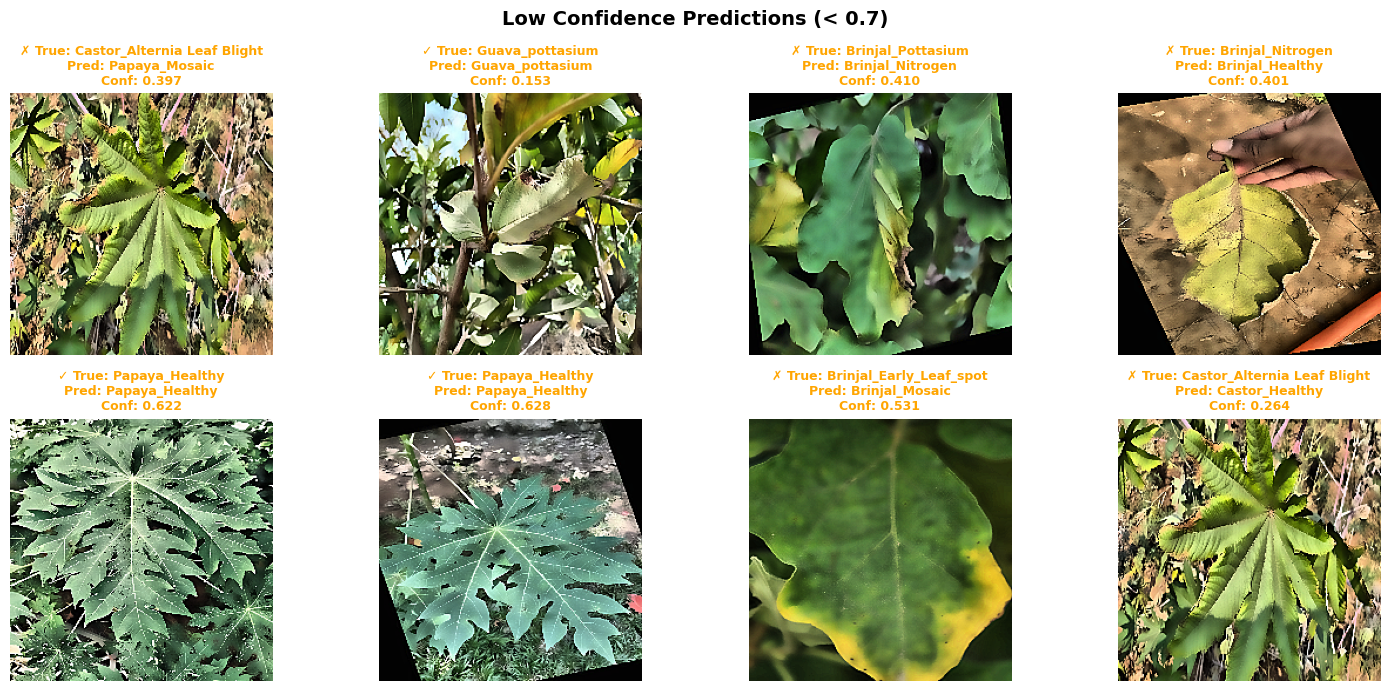

In [13]:
print("\n" + "="*70)
print("LOW CONFIDENCE PREDICTIONS")
print("="*70 + "\n")

# Get predictions with confidence < 0.7
low_conf_threshold = 0.7
low_conf_mask = (confidence < low_conf_threshold)
low_conf_count = low_conf_mask.sum()
low_conf_percentage = low_conf_count / len(confidence) * 100

print(f"Predictions with confidence < {low_conf_threshold}: {low_conf_count} ({low_conf_percentage:.2f}%)")

if low_conf_count > 0:
    low_conf_indices = np.where(low_conf_mask)[0]
    low_conf_accuracy = (pred_labels[low_conf_indices] == true_labels[low_conf_indices]).sum() / low_conf_count
    print(f"Accuracy on low confidence predictions: {low_conf_accuracy:.4f}")

    # Sample 8 low confidence predictions
    sample_low_conf_idx = np.random.choice(low_conf_indices, min(8, len(low_conf_indices)), replace=False)

    fig, axes = plt.subplots(2, 4, figsize=(15, 7))
    axes = axes.flatten()

    for plot_idx, img_idx in enumerate(sample_low_conf_idx):
        ax = axes[plot_idx]
        img = X_test[img_idx]

        ax.imshow(img)
        is_correct = "✓" if pred_labels[img_idx] == true_labels[img_idx] else "✗"
        ax.set_title(f"{is_correct} True: {true_labels[img_idx]}\nPred: {pred_labels[img_idx]}\nConf: {confidence[img_idx]:.3f}",
                     fontweight='bold', color='orange', fontsize=9)
        ax.axis('off')

    plt.suptitle(f'Low Confidence Predictions (< {low_conf_threshold})', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('../results/plots/low_confidence_predictions.png', dpi=300, bbox_inches='tight')
    print("✓ Saved: low_confidence_predictions.png")

## 9. Generate Prediction Report

In [14]:
print("\n" + "="*70)
print("GENERATING PREDICTION REPORT")
print("="*70 + "\n")

prediction_report = {
    'model': best_model_name,
    'test_set': {
        'total_samples': int(len(X_test)),
        'num_classes': int(num_classes)
    },
    'overall_performance': {
        'accuracy': float(accuracy),
        'mean_confidence': float(confidence.mean()),
        'min_confidence': float(confidence.min()),
        'max_confidence': float(confidence.max()),
        'std_confidence': float(confidence.std()),
        'correct_predictions': int(correct_mask.sum()),
        'incorrect_predictions': int((~correct_mask).sum())
    },
    'confidence_thresholds': {
        'high_confidence_0.9': int((confidence >= 0.9).sum()),
        'high_confidence_0.8': int((confidence >= 0.8).sum()),
        'medium_confidence_0.7': int((confidence >= 0.7).sum()),
        'low_confidence_below_0.7': int((confidence < 0.7).sum())
    }
}

with open('../results/reports/prediction_report.json', 'w') as f:
    json.dump(prediction_report, f, indent=4)

print("✓ Prediction report saved")
print(json.dumps(prediction_report, indent=2))


GENERATING PREDICTION REPORT

✓ Prediction report saved
{
  "model": "MobileNetV2",
  "test_set": {
    "total_samples": 860,
    "num_classes": 40
  },
  "overall_performance": {
    "accuracy": 0.9011627906976745,
    "mean_confidence": 0.8462883234024048,
    "min_confidence": 0.148912712931633,
    "max_confidence": 0.9999967813491821,
    "std_confidence": 0.19331899285316467,
    "correct_predictions": 775,
    "incorrect_predictions": 85
  },
  "confidence_thresholds": {
    "high_confidence_0.9": 502,
    "high_confidence_0.8": 609,
    "medium_confidence_0.7": 690,
    "low_confidence_below_0.7": 170
  }
}


## 10. Summary

In [ ]:
print("\n" + "="*70)
print("✓ PREDICTION TESTING COMPLETE")
print("="*70)

print(f"\n📊 Results Summary:")
print(f"  Model: {best_model_name}")
print(f"  Test Accuracy: {accuracy:.4f}")
print(f"  Correct Predictions: {correct_mask.sum()} / {len(X_test)}")
print(f"  Mean Confidence: {confidence.mean():.4f}")

print(f"\n💾 Files Saved:")
print(f"  - prediction_report.json")
print(f"  - per_class_prediction_stats.csv")
print(f"  - Visualization plots")

print(f"\n→ Next Step: 12_tflite_conversion.ipynb")